# Day 37: Veda Technology Business & Service Analytics

**Dataset:** the cleaned Veda Technology tables saved on Day 35
(`datasets/veda_business/cleaned/`)

This notebook is the third of four days in the Veda Technology Business & Service Analytics
project. It covers the marketing-channel performance analysis, customer segmentation, the
service demand analysis, and the business KPI dashboard, including the tables prepared for
the Power BI version of the dashboard.

## 1. Import Libraries and Load the Cleaned Tables

In [1]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

CLEAN_DIR = Path("../datasets/veda_business/cleaned")
POWERBI_DIR = Path("../datasets/veda_business/powerbi")
POWERBI_DIR.mkdir(parents=True, exist_ok=True)

visits = pd.read_csv(CLEAN_DIR / "website_visits_cleaned.csv", parse_dates=["visit_date"])
applications = pd.read_csv(CLEAN_DIR / "internship_applications_cleaned.csv", parse_dates=["application_date"])
training = pd.read_csv(CLEAN_DIR / "training_enrollments_cleaned.csv", parse_dates=["enrollment_date"])
it_inquiries = pd.read_csv(CLEAN_DIR / "it_service_inquiries_cleaned.csv", parse_dates=["inquiry_date"])
digital_inquiries = pd.read_csv(CLEAN_DIR / "digital_service_inquiries_cleaned.csv", parse_dates=["inquiry_date"])
requests = pd.read_csv(CLEAN_DIR / "service_requests_cleaned.csv", parse_dates=["request_date"])
marketing = pd.read_csv(CLEAN_DIR / "marketing_campaigns_cleaned.csv", parse_dates=["month"])

for name, table in [("website_visits", visits), ("internship_applications", applications), ("training_enrollments", training),
                    ("it_service_inquiries", it_inquiries), ("digital_service_inquiries", digital_inquiries),
                    ("service_requests", requests), ("marketing_campaigns", marketing)]:
    print(f"{name}: {table.shape[0]:,} rows, {table.shape[1]} columns")

marketing.head()

website_visits: 24,000 rows, 11 columns
internship_applications: 2,600 rows, 10 columns
training_enrollments: 1,800 rows, 10 columns
it_service_inquiries: 1,100 rows, 9 columns
digital_service_inquiries: 1,300 rows, 9 columns
service_requests: 3,200 rows, 8 columns
marketing_campaigns: 60 rows, 7 columns


,campaign_id,month,channel,spend_inr,impressions,clicks,leads
0,M00001,2025-10-01,Paid Ads,70800,324993,7567,447
1,M00002,2025-10-01,Social Media,33000,372838,5238,165
2,M00003,2025-10-01,Email,5300,74676,3203,295
3,M00004,2025-10-01,Organic Search,16100,161476,4325,253
4,M00005,2025-10-01,Referral,9800,64022,5417,516


## 2. Marketing-Channel Performance Analysis

The marketing table has one row per channel per month for the five channels that have a
marketing cost (Direct traffic has none). Four standard measures describe each channel: the
**click-through rate** (clicks per impression), the **cost per click**, the **lead rate**
(leads per click), and the **cost per lead**.

**Performance of each channel over the year**

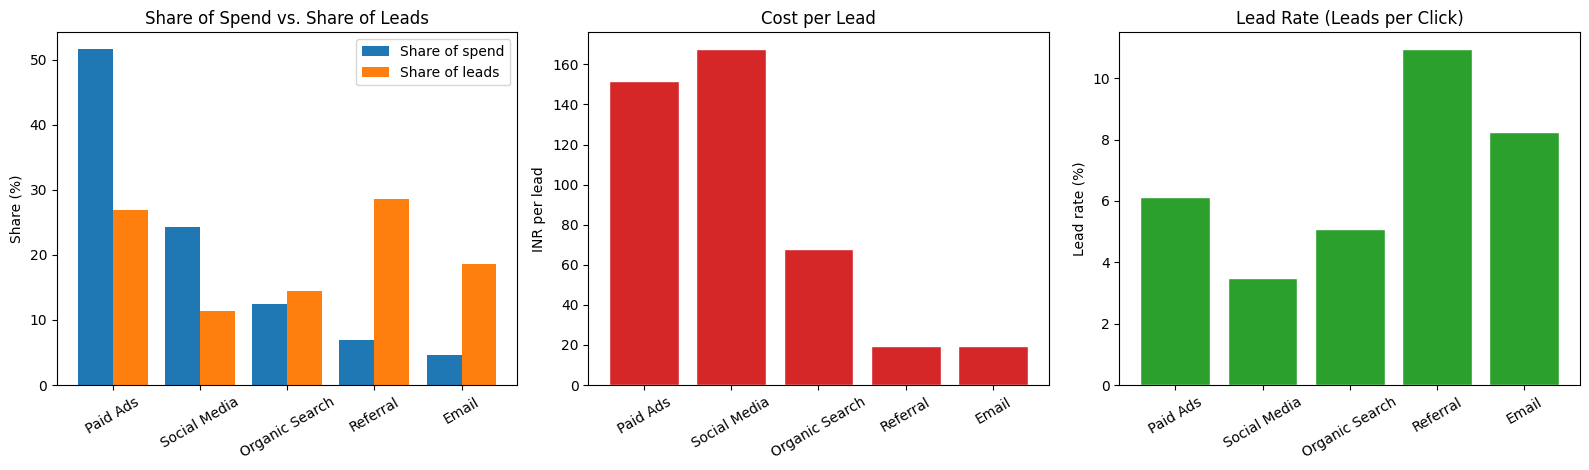

,spend_inr,impressions,clicks,leads,ctr_pct,cost_per_click_inr,lead_rate_pct,cost_per_lead_inr,spend_share_pct,lead_share_pct
channel,,,,,,,,,,
Paid Ads,824600,3981688,88604,5440,2.23,9.31,6.14,151.58,51.65,26.87
Social Media,388000,4514790,66481,2315,1.47,5.84,3.48,167.60,24.30,11.43
Organic Search,198800,1931047,57260,2922,2.97,3.47,5.10,68.04,12.45,14.43
Referral,111400,670027,52934,5794,7.90,2.10,10.95,19.23,6.98,28.62
Email,73600,1046787,45713,3774,4.37,1.61,8.26,19.50,4.61,18.64


In [2]:
channel_marketing = marketing.groupby("channel").agg(
    spend_inr=("spend_inr", "sum"), impressions=("impressions", "sum"), clicks=("clicks", "sum"), leads=("leads", "sum"),
)
channel_marketing["ctr_pct"] = channel_marketing["clicks"] / channel_marketing["impressions"] * 100
channel_marketing["cost_per_click_inr"] = channel_marketing["spend_inr"] / channel_marketing["clicks"]
channel_marketing["lead_rate_pct"] = channel_marketing["leads"] / channel_marketing["clicks"] * 100
channel_marketing["cost_per_lead_inr"] = channel_marketing["spend_inr"] / channel_marketing["leads"]
channel_marketing["spend_share_pct"] = channel_marketing["spend_inr"] / channel_marketing["spend_inr"].sum() * 100
channel_marketing["lead_share_pct"] = channel_marketing["leads"] / channel_marketing["leads"].sum() * 100
channel_marketing = channel_marketing.round(2).sort_values("spend_inr", ascending=False)

x = np.arange(len(channel_marketing))
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
axes[0].bar(x - 0.2, channel_marketing["spend_share_pct"], 0.4, label="Share of spend")
axes[0].bar(x + 0.2, channel_marketing["lead_share_pct"], 0.4, label="Share of leads")
axes[0].set_xticks(x)
axes[0].set_xticklabels(channel_marketing.index, rotation=30)
axes[0].set_ylabel("Share (%)")
axes[0].set_title("Share of Spend vs. Share of Leads")
axes[0].legend()
axes[1].bar(channel_marketing.index, channel_marketing["cost_per_lead_inr"], edgecolor="white", color="tab:red")
axes[1].set_title("Cost per Lead")
axes[1].set_ylabel("INR per lead")
axes[1].tick_params(axis="x", rotation=30)
axes[2].bar(channel_marketing.index, channel_marketing["lead_rate_pct"], edgecolor="white", color="tab:green")
axes[2].set_title("Lead Rate (Leads per Click)")
axes[2].set_ylabel("Lead rate (%)")
axes[2].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

channel_marketing

**Monthly spend, leads, and cost per lead**

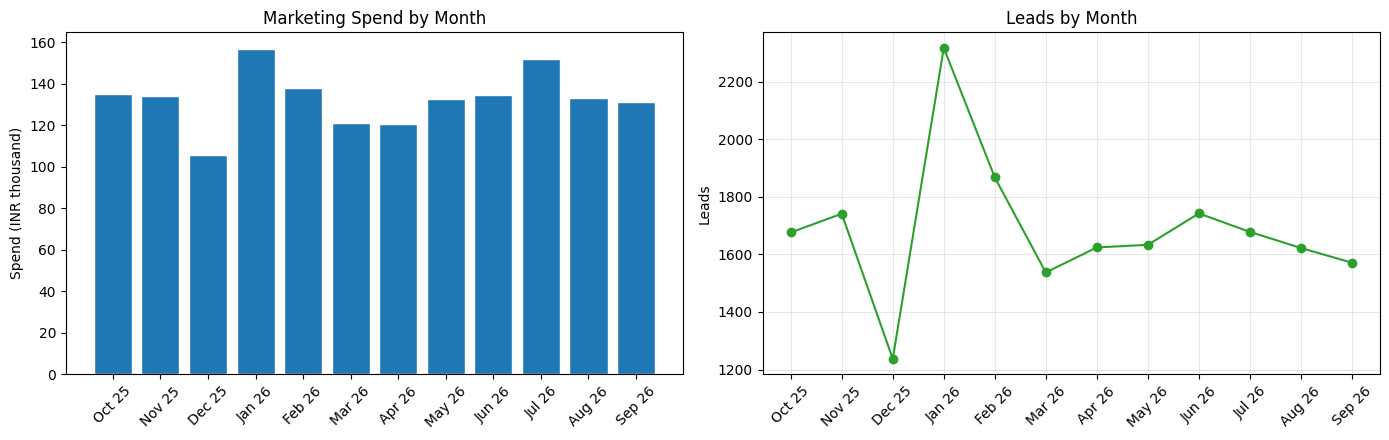

Correlation between monthly spend and monthly leads: 0.83


,spend_inr,clicks,leads,cost_per_lead_inr
month,,,,
2025-10-01,135000,25750,1676,80.55
2025-11-01,134300,24454,1741,77.14
2025-12-01,105700,19573,1237,85.45
2026-01-01,157000,34620,2317,67.76
2026-02-01,138100,27041,1867,73.97
2026-03-01,121200,22900,1537,78.85
2026-04-01,120700,26109,1624,74.32
2026-05-01,132800,24789,1633,81.32
2026-06-01,134600,27428,1742,77.27


In [3]:
monthly_marketing = marketing.groupby("month").agg(spend_inr=("spend_inr", "sum"), clicks=("clicks", "sum"), leads=("leads", "sum"))
monthly_marketing["cost_per_lead_inr"] = (monthly_marketing["spend_inr"] / monthly_marketing["leads"]).round(2)
month_labels = monthly_marketing.index.strftime("%b %y")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].bar(month_labels, monthly_marketing["spend_inr"] / 1000, edgecolor="white")
axes[0].set_title("Marketing Spend by Month")
axes[0].set_ylabel("Spend (INR thousand)")
axes[0].tick_params(axis="x", rotation=45)
axes[1].plot(month_labels, monthly_marketing["leads"], marker="o", color="tab:green")
axes[1].set_title("Leads by Month")
axes[1].set_ylabel("Leads")
axes[1].tick_params(axis="x", rotation=45)
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

corr_spend_leads = monthly_marketing["spend_inr"].corr(monthly_marketing["leads"])
print(f"Correlation between monthly spend and monthly leads: {corr_spend_leads:.2f}")
monthly_marketing

**Linking marketing cost to what happens on the website**

The leads reported by the marketing platforms are a separate count from the conversions
recorded on the website, so both are shown. Dividing each channel's spend by its website
visits and website conversions gives a second view of cost.

In [4]:
web_by_channel = visits.groupby("channel").agg(web_visits=("visit_id", "count"), web_conversions=("converted", "sum"))
web_by_channel["web_conversion_rate_pct"] = web_by_channel["web_conversions"] / web_by_channel["web_visits"] * 100

marketing_vs_web = channel_marketing[["spend_inr", "leads", "cost_per_lead_inr"]].join(web_by_channel)
marketing_vs_web["cost_per_visit_inr"] = marketing_vs_web["spend_inr"] / marketing_vs_web["web_visits"]
marketing_vs_web["cost_per_web_conversion_inr"] = marketing_vs_web["spend_inr"] / marketing_vs_web["web_conversions"]
marketing_vs_web = marketing_vs_web.round(2).sort_values("cost_per_web_conversion_inr")
marketing_vs_web

,spend_inr,leads,cost_per_lead_inr,web_visits,web_conversions,web_conversion_rate_pct,cost_per_visit_inr,cost_per_web_conversion_inr
channel,,,,,,,,
Email,73600,3774,19.50,1910,160,8.38,38.53,460.00
Organic Search,198800,2922,68.04,7674,252,3.28,25.91,788.89
Referral,111400,5794,19.23,2157,137,6.35,51.65,813.14
Social Media,388000,2315,167.60,5734,98,1.71,67.67,3959.18
Paid Ads,824600,5440,151.58,3216,66,2.05,256.41,12493.94


**Observation:** the five channels cost INR 1,596K in total and produced 20,245 leads, an
average of INR 79 per lead, and monthly spend and leads rise and fall together (correlation
0.83). The money is not going where the leads are. Paid Ads takes 51.6% of the spend but
delivers 26.9% of the leads, and Social Media takes 24.3% of the spend for 11.4% of the
leads, so the two together use 76% of the budget for 38% of the leads. Social Media is the
weakest channel on the measures that matter most: the lowest click-through rate (1.47%), the
lowest lead rate (3.48%), and the highest cost per lead (INR 168, versus INR 152 for Paid
Ads). Referral is the opposite: only 7.0% of the spend produces the largest share of leads
(28.6%) at INR 19 per lead, with a click-through rate of 7.9% and a lead rate of 10.9%, and
Email is nearly as efficient (INR 20 per lead). Organic Search sits in the middle (INR 68).
The website tells the same story: a website conversion costs INR 460 through Email, about
INR 789 through Organic Search and INR 813 through Referral, but INR 3,959 through Social
Media and INR 12,494 through Paid Ads, about 27 times the Email cost. Over the year, the
cost per lead was lowest in January 2026 (INR 68) and highest in July 2026 (INR 91). These
figures come from the assumptions in the simulation, so they show how to read a marketing
analysis and are not advice about Veda Technology's real campaigns.

## 3. Customer Segmentation

Two kinds of segmentation are used: a **behavioral** segmentation of website visitors with
k-means clustering, and a **value-based** segmentation of service inquiries with budget
bands.

**Segment 1: website visitors grouped by how they browse**

Visitors are clustered on two behaviors, the number of pages viewed and the session
duration. Durations are skewed, so the logarithm is used, and both features are standardized
so neither dominates. The number of segments is chosen by comparing silhouette scores
(higher means better separated clusters) on a random sample of 5,000 visits.

In [5]:
behavior = pd.DataFrame({"pages_viewed": visits["pages_viewed"], "log_duration": np.log1p(visits["session_duration_sec"])})
features = StandardScaler().fit_transform(behavior)

sample_rows = np.random.default_rng(42).choice(len(features), size=5000, replace=False)
silhouette = {}
for k in range(2, 7):
    labels = KMeans(n_clusters=k, n_init=10, random_state=42).fit_predict(features)
    silhouette[k] = silhouette_score(features[sample_rows], labels[sample_rows])

silhouette_table = pd.Series(silhouette, name="silhouette_score").round(3)

# Does the best-scoring 2-segment solution just recreate the existing bounce flag?
two_segments = KMeans(n_clusters=2, n_init=10, random_state=42).fit_predict(features)
agreement_with_bounce = max((two_segments == visits["bounced"]).mean(), (two_segments != visits["bounced"]).mean())
print(f"The 2-segment solution agrees with the bounced flag for {agreement_with_bounce * 100:.1f}% of visits")

silhouette_table.to_frame()

The 2-segment solution agrees with the bounced flag for 99.3% of visits


,silhouette_score
2,0.661
3,0.584
4,0.486
5,0.457
6,0.455


**Observation:** the silhouette score is highest for 2 segments (0.66) and falls as segments
are added (0.58 for 3 and 0.49 for 4). The 2-segment solution, however, only separates
visits that bounce from visits that do not: it agrees with the existing `bounced` flag for
99.3% of visits, so it adds nothing the data did not already say. Three segments still score
well (a score above 0.5 is commonly read as reasonable structure) and split the visitors who
stay into two useful groups, so 3 segments are used. This is a judgment call, not a result
that the score alone gives.

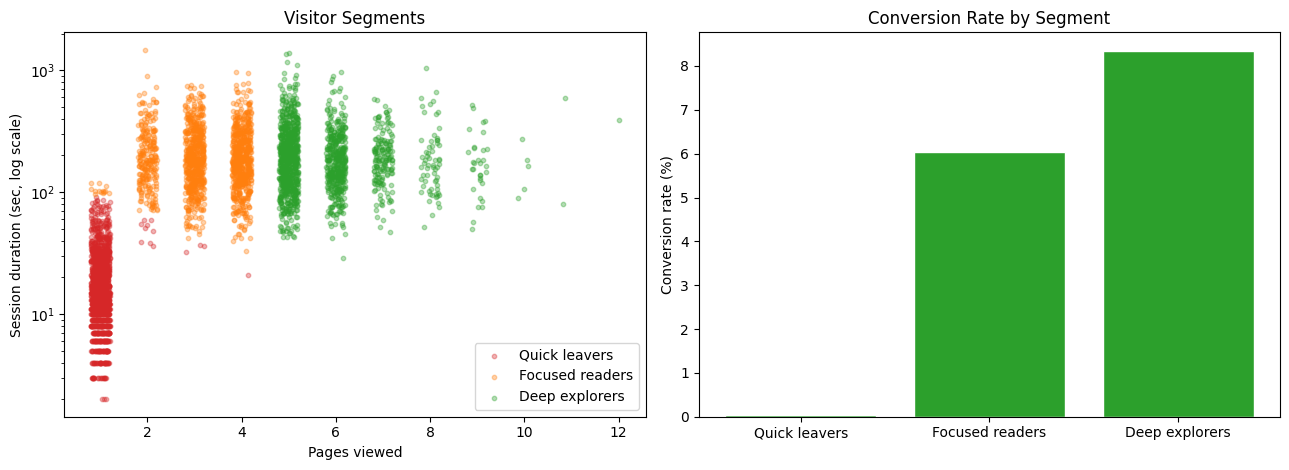

,visits,avg_pages,avg_duration_sec,bounce_rate_pct,conversion_rate_pct,mobile_share_pct,share_of_visits_pct,share_of_conversions_pct,top_channel
segment_id,,,,,,,,,
Quick leavers,11451,1.01,20.50,99.39,0.05,69.27,47.71,0.69,Social Media
Focused readers,7793,3.25,216.85,0.94,6.04,57.58,32.47,53.89,Organic Search
Deep explorers,4756,5.77,215.45,0.00,8.35,56.22,19.82,45.42,Organic Search


In [6]:
N_SEGMENTS = 3
visits["segment_id"] = KMeans(n_clusters=N_SEGMENTS, n_init=10, random_state=42).fit_predict(features)

segment_profile = visits.groupby("segment_id").agg(
    visits=("visit_id", "count"), avg_pages=("pages_viewed", "mean"), avg_duration_sec=("session_duration_sec", "mean"),
    bounce_rate_pct=("bounced", "mean"), conversion_rate_pct=("converted", "mean"),
    mobile_share_pct=("device", lambda s: (s == "Mobile").mean()),
)
for col in ["bounce_rate_pct", "conversion_rate_pct", "mobile_share_pct"]:
    segment_profile[col] *= 100

# Name the segments from the fewest to the most pages viewed
SEGMENT_NAMES = ["Quick leavers", "Focused readers", "Deep explorers"]
order = segment_profile["avg_pages"].sort_values().index
names = dict(zip(order, SEGMENT_NAMES))
visits["segment"] = visits["segment_id"].map(names)
segment_profile.index = segment_profile.index.map(names)
segment_profile = segment_profile.loc[SEGMENT_NAMES]
segment_profile["share_of_visits_pct"] = segment_profile["visits"] / len(visits) * 100
segment_profile["share_of_conversions_pct"] = visits.groupby("segment")["converted"].sum().reindex(segment_profile.index) / visits["converted"].sum() * 100
segment_profile = segment_profile.round(2)

top_channel = visits.groupby("segment")["channel"].agg(lambda s: s.value_counts().idxmax()).reindex(segment_profile.index)
segment_profile["top_channel"] = top_channel

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for name, color in zip(segment_profile.index, ["tab:red", "tab:orange", "tab:green"]):
    chunk = visits[visits["segment"] == name].sample(min(1500, (visits["segment"] == name).sum()), random_state=42)
    axes[0].scatter(chunk["pages_viewed"] + np.random.default_rng(1).uniform(-0.2, 0.2, len(chunk)), chunk["session_duration_sec"],
                    alpha=0.35, s=10, label=name, color=color)
axes[0].set_yscale("log")
axes[0].set_xlabel("Pages viewed")
axes[0].set_ylabel("Session duration (sec, log scale)")
axes[0].set_title("Visitor Segments")
axes[0].legend()
axes[1].bar(segment_profile.index, segment_profile["conversion_rate_pct"], edgecolor="white", color="tab:green")
axes[1].set_title("Conversion Rate by Segment")
axes[1].set_ylabel("Conversion rate (%)")
plt.tight_layout()
plt.show()

segment_profile

**Observation:** the three segments behave very differently. **Quick leavers** are 47.7% of
all visits but almost never convert (0.05%), providing just 0.7% of conversions: they view
about one page, stay around 20 seconds, are mostly on mobile (69%), and come most often from
Social Media. The visitors who stay split into two groups that spend the same time on the
site (about 3.6 minutes) but browse differently. **Focused readers** view about 3.2 pages
(32.5% of visits, a 6.04% conversion rate, 53.9% of conversions), while **Deep explorers**
view about 5.8 pages and convert best (8.35%), making up only 19.8% of visits but 45.4% of
conversions. One caution: only visitors who do not bounce can convert, and the simulation
raised the conversion chance for visitors who view five or more pages, so these conversion
gaps are partly built in. The practical message is where to look for gains: nearly half of
all visits leave after a single page, so reducing bounces, especially on mobile, is the
largest opportunity on the site.

**Segment 2: service inquiries grouped by budget**

The IT and digital inquiries are combined, then split into three budget bands: **Small**
(under INR 50,000), **Medium** (INR 50,000 to 500,000), and **Large** (over INR 500,000).

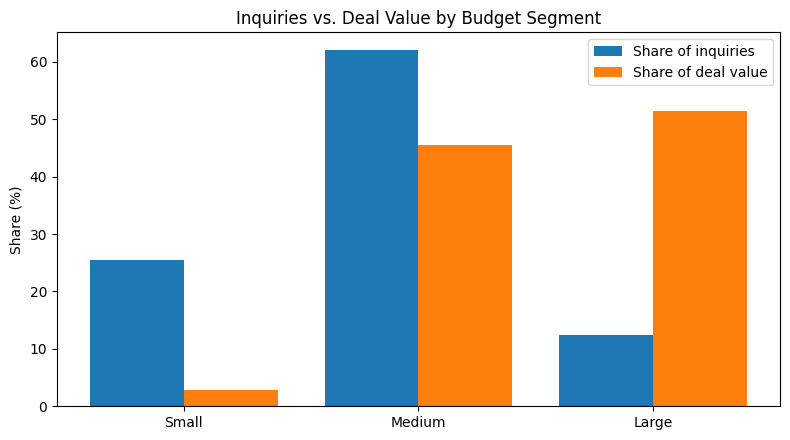

                inquiries  conversion_rate_pct  avg_response_hours  \
budget_segment                                                       
Small                 612                42.32                8.03   
Medium               1489                45.13                8.32   
Large                 299                44.48                8.32   

                deal_value_inr  share_of_inquiries_pct  \
budget_segment                                           
Small                  7059000                   25.50   
Medium               109947000                   62.04   
Large                124355000                   12.46   

                share_of_deal_value_pct  
budget_segment                           
Small                              2.92  
Medium                            45.55  
Large                             51.52  

Service line mix inside each segment (%)
service_line    Digital services  IT services
budget_segment                               
Small         

In [7]:
inquiries = pd.concat([
    it_inquiries.assign(service_line="IT services"), digital_inquiries.assign(service_line="Digital services"),
], ignore_index=True)
inquiries["is_converted"] = (inquiries["status"] == "Converted").astype(int)
inquiries["budget_segment"] = pd.cut(
    inquiries["budget_inr"], bins=[0, 50000, 500000, np.inf],
    labels=["Small", "Medium", "Large"], right=False,
)

budget_profile = inquiries.groupby("budget_segment", observed=True).agg(
    inquiries=("inquiry_id", "count"), conversion_rate_pct=("is_converted", "mean"),
    avg_response_hours=("response_time_hours", "mean"), deal_value_inr=("deal_value_inr", "sum"),
)
budget_profile["conversion_rate_pct"] *= 100
budget_profile["share_of_inquiries_pct"] = budget_profile["inquiries"] / len(inquiries) * 100
budget_profile["share_of_deal_value_pct"] = budget_profile["deal_value_inr"] / budget_profile["deal_value_inr"].sum() * 100
budget_profile = budget_profile.round(2)

x = np.arange(len(budget_profile))
plt.figure(figsize=(8, 4.5))
plt.bar(x - 0.2, budget_profile["share_of_inquiries_pct"], 0.4, label="Share of inquiries")
plt.bar(x + 0.2, budget_profile["share_of_deal_value_pct"], 0.4, label="Share of deal value")
plt.xticks(x, budget_profile.index)
plt.ylabel("Share (%)")
plt.title("Inquiries vs. Deal Value by Budget Segment")
plt.legend()
plt.tight_layout()
plt.show()

print(budget_profile)
print("\nService line mix inside each segment (%)")
print((pd.crosstab(inquiries["budget_segment"], inquiries["service_line"], normalize="index") * 100).round(1))
print("\nClient type mix inside each segment (%)")
print((pd.crosstab(inquiries["budget_segment"], inquiries["client_type"], normalize="index") * 100).round(1))

**Observation:** value is far more concentrated than volume. Large inquiries (over INR 500K)
are only 12.5% of inquiries (299 of them) but bring 51.5% of the deal value, while Small
inquiries are 25.5% of the volume and just 2.9% of the value, and Medium inquiries sit in
the middle (62.0% of inquiries, 45.5% of value). The win rates are similar (42.3% for Small,
45.1% for Medium, 44.5% for Large) and so are response times (8.0 to 8.3 hours), so the
concentration comes from the size of the deals and not from winning more often. The segments
also map onto the business lines: every Large inquiry is for an IT service, 46% of them from
Enterprise clients and 38% from SMEs, while 83% of Small inquiries are for digital services.
A sensible use of the segments would be to give Large inquiries the fastest and most senior
response, since each one is worth far more than the others.

## 4. Service Demand Analysis

Demand is measured by what customers actually ask for: internship applications, training
enrollments, IT inquiries, and digital inquiries.

**Monthly demand for each business line**

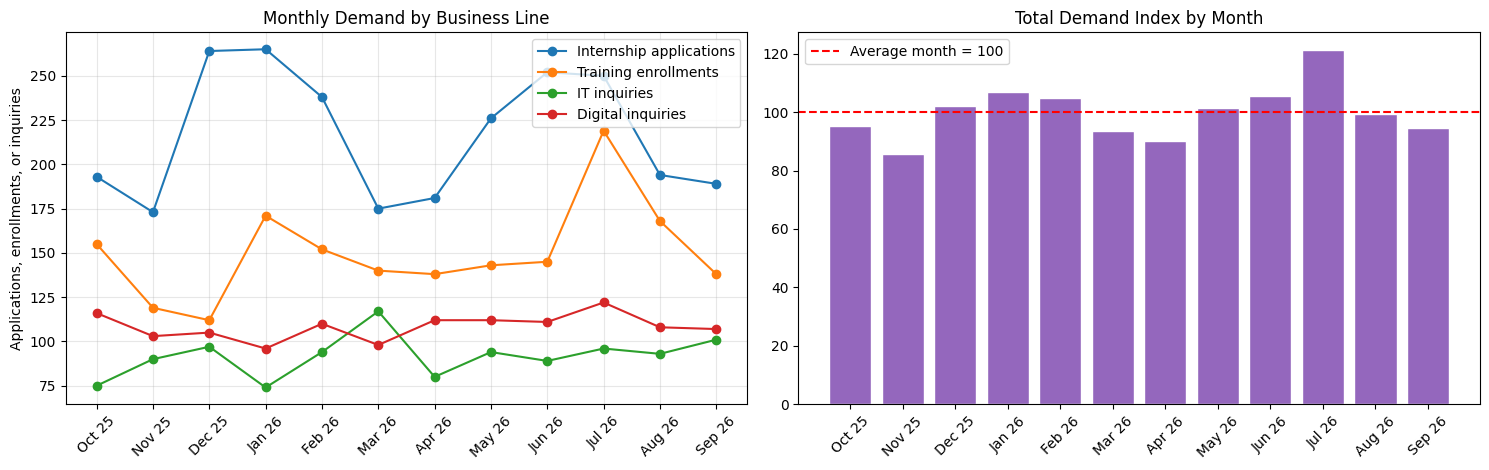

,total_demand,first_half,second_half,share_of_demand_pct,growth_second_vs_first_half_pct,peak_month
Internship applications,2600,1308,1292,38.2,-1.2,Jan 2026
Training enrollments,1800,849,951,26.5,12.0,Jul 2026
IT inquiries,1100,547,553,16.2,1.1,Mar 2026
Digital inquiries,1300,628,672,19.1,7.0,Jul 2026


In [8]:
def monthly_count(table, date_column, label):
    return table.groupby(table[date_column].dt.to_period("M")).size().rename(label)


demand_monthly = pd.concat([
    monthly_count(applications, "application_date", "Internship applications"),
    monthly_count(training, "enrollment_date", "Training enrollments"),
    monthly_count(it_inquiries, "inquiry_date", "IT inquiries"),
    monthly_count(digital_inquiries, "inquiry_date", "Digital inquiries"),
], axis=1)
demand_monthly["Total demand"] = demand_monthly.sum(axis=1)
demand_monthly["Demand index"] = (demand_monthly["Total demand"] / demand_monthly["Total demand"].mean() * 100).round(1)

lines = ["Internship applications", "Training enrollments", "IT inquiries", "Digital inquiries"]
line_summary = pd.DataFrame({
    "total_demand": demand_monthly[lines].sum(),
    "first_half": demand_monthly[lines].iloc[:6].sum(),
    "second_half": demand_monthly[lines].iloc[6:].sum(),
})
line_summary["share_of_demand_pct"] = line_summary["total_demand"] / line_summary["total_demand"].sum() * 100
line_summary["growth_second_vs_first_half_pct"] = (line_summary["second_half"] / line_summary["first_half"] - 1) * 100
line_summary["peak_month"] = [demand_monthly[line].idxmax().strftime("%b %Y") for line in line_summary.index]
line_summary = line_summary.round(1)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
labels = demand_monthly.index.strftime("%b %y")
for line in lines:
    axes[0].plot(labels, demand_monthly[line], marker="o", label=line)
axes[0].set_title("Monthly Demand by Business Line")
axes[0].set_ylabel("Applications, enrollments, or inquiries")
axes[0].tick_params(axis="x", rotation=45)
axes[0].legend()
axes[0].grid(alpha=0.3)
axes[1].bar(labels, demand_monthly["Demand index"], edgecolor="white", color="tab:purple")
axes[1].axhline(100, color="red", linestyle="--", label="Average month = 100")
axes[1].set_title("Total Demand Index by Month")
axes[1].tick_params(axis="x", rotation=45)
axes[1].legend()
plt.tight_layout()
plt.show()

line_summary

**Which individual services are in the highest demand?**

Every service across the four business lines is put into one table, ranked by the number of
applications, enrollments, or inquiries, and also by the money it brings in. Internships
have no fee in the data, so their value is left empty.

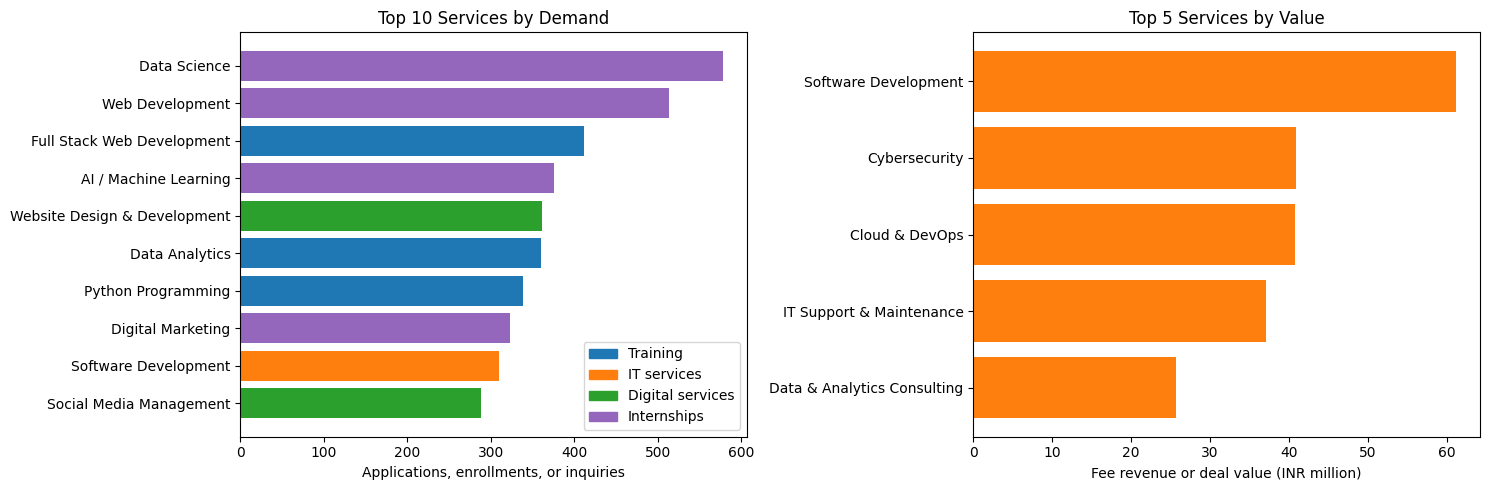

Top 10 by demand
   business_line                      service  demand  value_inr
     Internships                 Data Science     578        NaN
     Internships              Web Development     513        NaN
        Training   Full Stack Web Development     412  7027200.0
     Internships        AI / Machine Learning     376        NaN
Digital services Website Design & Development     361  8953000.0
        Training               Data Analytics     360  5118000.0
        Training           Python Programming     339  2889000.0
     Internships            Digital Marketing     323        NaN
     IT services         Software Development     310 61166000.0
Digital services      Social Media Management     288  7296000.0

Top 5 by value
business_line                     service  demand  value_inr
  IT services        Software Development     310 61166000.0
  IT services               Cybersecurity     142 40905000.0
  IT services              Cloud & DevOps     190 40821000.0
  IT ser

In [9]:
def service_table(table, column, id_column, value_column, line):
    result = table.groupby(column).agg(demand=(id_column, "count"))
    result["value_inr"] = table.groupby(column)[value_column].sum() if value_column else np.nan
    result = result.reset_index().rename(columns={column: "service"})
    result.insert(0, "business_line", line)
    return result


service_demand = pd.concat([
    service_table(training, "program", "enrollment_id", "fee_inr", "Training"),
    service_table(it_inquiries, "service_type", "inquiry_id", "deal_value_inr", "IT services"),
    service_table(digital_inquiries, "service_type", "inquiry_id", "deal_value_inr", "Digital services"),
    service_table(applications, "domain", "application_id", None, "Internships"),
], ignore_index=True).sort_values("demand", ascending=False).reset_index(drop=True)
service_demand["demand_rank"] = service_demand.index + 1

top_by_demand = service_demand.head(10)
top_by_value = service_demand.dropna(subset=["value_inr"]).sort_values("value_inr", ascending=False).head(5)

colors = {"Training": "tab:blue", "IT services": "tab:orange", "Digital services": "tab:green", "Internships": "tab:purple"}
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].barh(top_by_demand["service"][::-1], top_by_demand["demand"][::-1], color=[colors[b] for b in top_by_demand["business_line"][::-1]])
axes[0].set_title("Top 10 Services by Demand")
axes[0].set_xlabel("Applications, enrollments, or inquiries")
axes[1].barh(top_by_value["service"][::-1], top_by_value["value_inr"][::-1] / 1e6, color=[colors[b] for b in top_by_value["business_line"][::-1]])
axes[1].set_title("Top 5 Services by Value")
axes[1].set_xlabel("Fee revenue or deal value (INR million)")
handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in colors.values()]
axes[0].legend(handles, colors.keys(), loc="lower right")
plt.tight_layout()
plt.show()

print("Top 10 by demand")
print(top_by_demand[["business_line", "service", "demand", "value_inr"]].to_string(index=False))
print("\nTop 5 by value")
print(top_by_value[["business_line", "service", "demand", "value_inr"]].to_string(index=False))

**Observation:** across the four business lines there were 6,800 applications, enrollments,
and inquiries. Internship applications are the largest share (38.2%), followed by training
enrollments (26.5%), digital inquiries (19.1%), and IT inquiries (16.2%). Demand is
seasonal: total demand peaks in July 2026 (index 121, driven by training and digital) and is
lowest in November 2025 (index 86), and 6 of the 12 months are above average. Each line has
its own peak: internships in Jan 2026, IT in Mar 2026, and training and digital in Jul 2026.
Comparing the second half of the year with the first, training grew 12.0% and digital 7.0%,
IT is flat (+1.1%), and internship applications slipped (-1.2%). By individual service, the
demand ranking is dominated by internships and training: the top 10 hold 4 internship
domains, 3 training programs, 2 digital services, and only 1 IT service, and Data Science
tops the list with 578 applications. Ranking by money flips the picture completely: the top
five are all IT services, led by Software Development (INR 61.2 million) and Cybersecurity
(INR 40.9 million), even though Cybersecurity ranks only number 23 by demand. The services
people ask for most are not the ones that bring in the most revenue.

**Where does demand come from?**

The same six channels are recorded for website conversions, IT inquiries, digital inquiries,
and training enrollments, so the origin of demand can be compared across them. (Internship
applications use a different list of sources, which were analyzed on Day 35.)

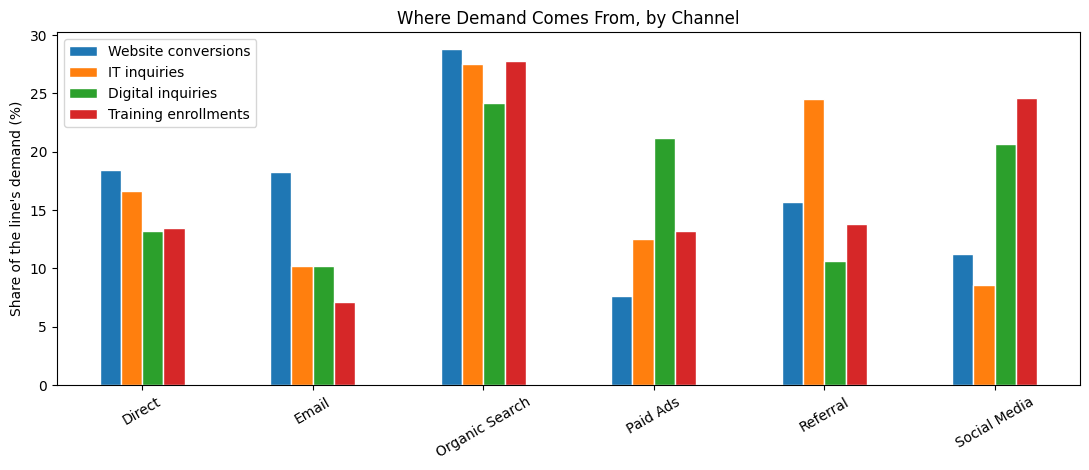

Counts
                Website conversions  IT inquiries  Digital inquiries  \
Direct                          161           183                171   
Email                           160           112                132   
Organic Search                  252           302                315   
Paid Ads                         66           138                275   
Referral                        137           270                138   
Social Media                     98            95                269   

                Training enrollments  
Direct                           243  
Email                            128  
Organic Search                   501  
Paid Ads                         237  
Referral                         248  
Social Media                     443  

Share of each line's demand (%)
                Website conversions  IT inquiries  Digital inquiries  \
Direct                         18.4          16.6               13.2   
Email                          18.3   

In [10]:
channel_demand = pd.DataFrame({
    "Website conversions": visits.groupby("channel")["converted"].sum(),
    "IT inquiries": it_inquiries["channel"].value_counts(),
    "Digital inquiries": digital_inquiries["channel"].value_counts(),
    "Training enrollments": training["lead_source"].value_counts(),
}).fillna(0).astype(int)
channel_demand_share = (channel_demand / channel_demand.sum() * 100).round(1)

channel_demand_share.plot(kind="bar", figsize=(11, 4.8), edgecolor="white")
plt.ylabel("Share of the line's demand (%)")
plt.title("Where Demand Comes From, by Channel")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

print("Counts")
print(channel_demand)
print("\nShare of each line's demand (%)")
print(channel_demand_share)

**Observation:** Organic Search is the largest source of demand in every line (24.2% to
28.8%), but beyond that, each line has its own mix. IT demand is driven by relationships:
Referral supplies 24.5% of IT inquiries, against 10.6% of digital inquiries and 13.8% of
training enrollments, and Organic Search and Referral together supply 52% of IT inquiries.
Digital demand is driven by online channels: Social Media and Paid Ads together bring 42% of
digital inquiries, against 21% of IT inquiries. Social Media is also a major source of
training enrollments (24.6%), even though it produces only 11.2% of website conversions and
8.6% of IT inquiries, and Paid Ads shows a similar split (21.2% of digital inquiries versus
7.6% of website conversions). Email, in contrast, is 18.3% of website conversions but only
7.1% of training enrollments. A channel's value depends on which business line you are
measuring, which is why the marketing view alone can be misleading.

## 5. Business KPI Dashboard

The dashboard brings the main measures of every business area onto one page. This notebook
builds the **KPI scorecard**, a **static dashboard** in Python, and the **tables for the
Power BI version** (the Power BI file itself is built in Power BI Desktop, following the
step-by-step guide in `power_bi_dashboard_guide.md`).

**The KPI scorecard**

In [11]:
closed_requests = requests[requests["status"] != "Open"]
converted_it = it_inquiries[it_inquiries["status"] == "Converted"]
converted_digital = digital_inquiries[digital_inquiries["status"] == "Converted"]
selected = applications[applications["status"] == "Selected"]

kpi_rows = [
    ("Website", "Total visits", len(visits), "visits"),
    ("Website", "Bounce rate", visits["bounced"].mean() * 100, "%"),
    ("Website", "Conversion rate", visits["converted"].mean() * 100, "%"),
    ("Website", "Average session duration", visits["session_duration_sec"].mean() / 60, "minutes"),
    ("Internships", "Applications", len(applications), "applications"),
    ("Internships", "Selection rate", len(selected) / len(applications) * 100, "%"),
    ("Internships", "Enrollment rate (of selected)", selected["enrolled"].sum() / len(selected) * 100, "%"),
    ("Training", "Enrollments", len(training), "enrollments"),
    ("Training", "Fee revenue", training["fee_inr"].sum() / 1e6, "INR million"),
    ("Training", "Completion rate", training["completed"].mean() * 100, "%"),
    ("Training", "Average satisfaction", training["satisfaction_rating"].mean(), "out of 5"),
    ("IT services", "Inquiries", len(it_inquiries), "inquiries"),
    ("IT services", "Conversion rate", len(converted_it) / len(it_inquiries) * 100, "%"),
    ("IT services", "Deal value", it_inquiries["deal_value_inr"].sum() / 1e6, "INR million"),
    ("Digital services", "Inquiries", len(digital_inquiries), "inquiries"),
    ("Digital services", "Conversion rate", len(converted_digital) / len(digital_inquiries) * 100, "%"),
    ("Digital services", "Deal value", digital_inquiries["deal_value_inr"].sum() / 1e6, "INR million"),
    ("Service requests", "Total requests", len(requests), "requests"),
    ("Service requests", "Resolved", (requests["status"] == "Resolved").mean() * 100, "%"),
    ("Service requests", "Escalated", (requests["status"] == "Escalated").mean() * 100, "%"),
    ("Service requests", "Average resolution time", closed_requests["resolution_time_hours"].mean(), "hours"),
    ("Service requests", "Average satisfaction", requests["satisfaction_rating"].mean(), "out of 5"),
    ("Marketing", "Total spend", marketing["spend_inr"].sum() / 1e6, "INR million"),
    ("Marketing", "Leads", marketing["leads"].sum(), "leads"),
    ("Marketing", "Cost per lead", marketing["spend_inr"].sum() / marketing["leads"].sum(), "INR"),
    ("Marketing", "Click-through rate", marketing["clicks"].sum() / marketing["impressions"].sum() * 100, "%"),
]
kpi_summary = pd.DataFrame(kpi_rows, columns=["business_area", "kpi", "value", "unit"])
kpi_summary["value"] = kpi_summary["value"].round(2)
kpi_summary

,business_area,kpi,value,unit
0,Website,Total visits,24000.00,visits
1,Website,Bounce rate,47.72,%
2,Website,Conversion rate,3.64,%
3,Website,Average session duration,2.05,minutes
4,Internships,Applications,2600.00,applications
5,Internships,Selection rate,36.08,%
6,Internships,Enrollment rate (of selected),84.54,%
7,Training,Enrollments,1800.00,enrollments
8,Training,Fee revenue,24.07,INR million
9,Training,Completion rate,65.78,%


**A static dashboard in Python**

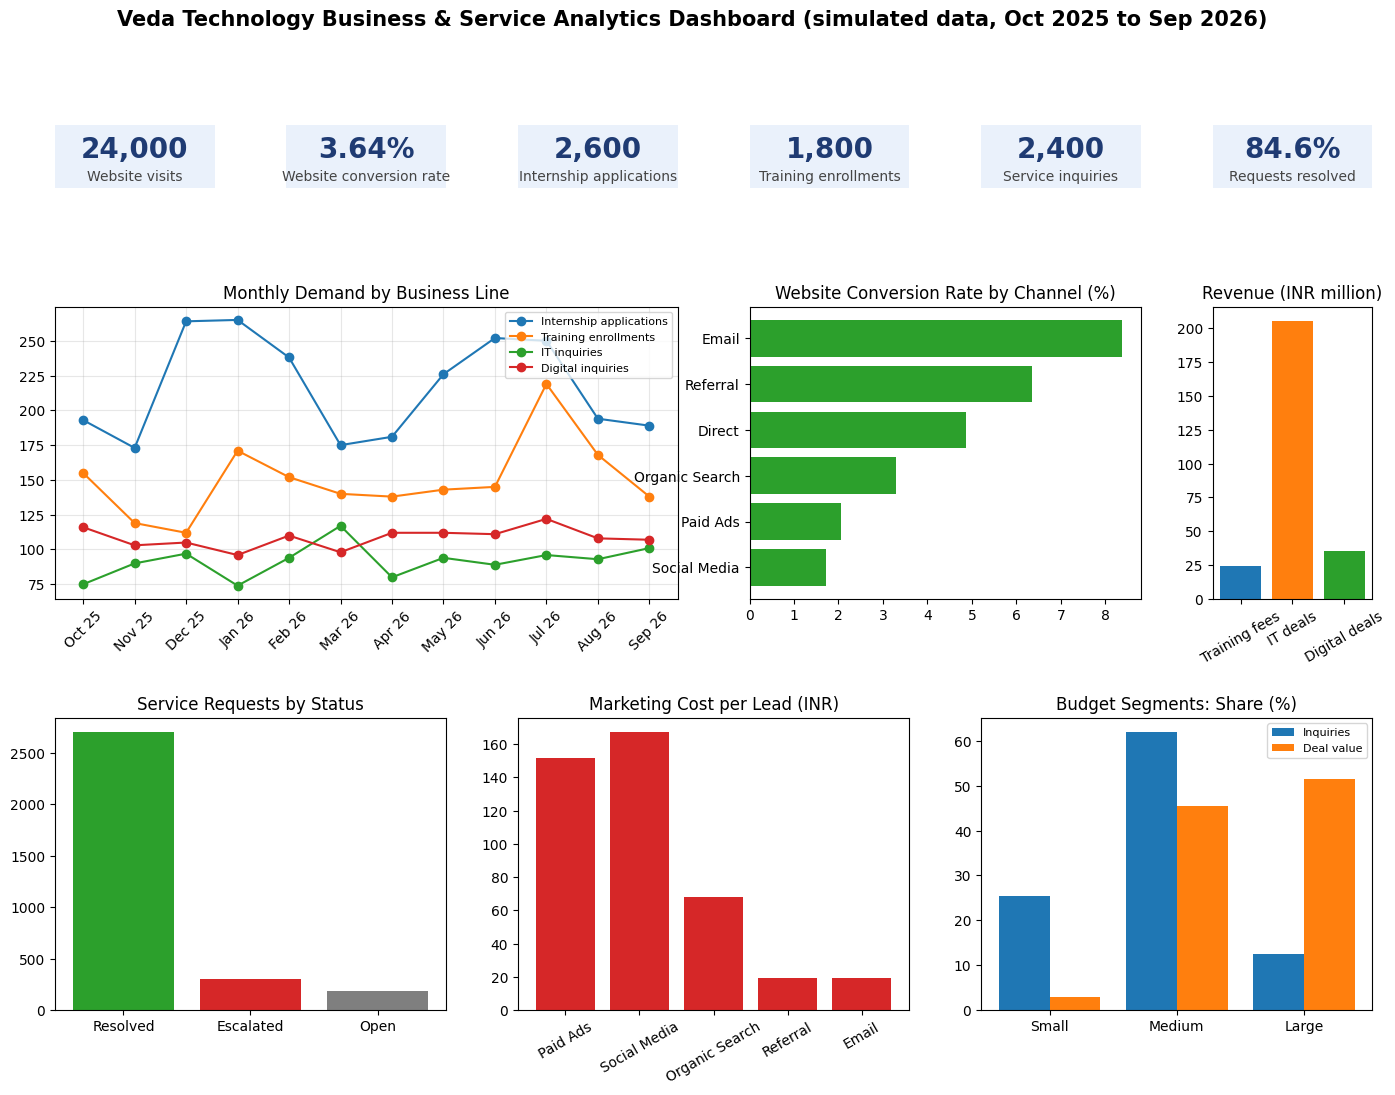

In [12]:
fig = plt.figure(figsize=(17, 11.5))
grid = fig.add_gridspec(3, 6, height_ratios=[0.65, 3, 3], hspace=0.55, wspace=0.45)
kpi = kpi_summary.set_index(["business_area", "kpi"])["value"]

cards = [
    ("Website visits", f"{kpi[('Website', 'Total visits')]:,.0f}"),
    ("Website conversion rate", f"{kpi[('Website', 'Conversion rate')]:.2f}%"),
    ("Internship applications", f"{kpi[('Internships', 'Applications')]:,.0f}"),
    ("Training enrollments", f"{kpi[('Training', 'Enrollments')]:,.0f}"),
    ("Service inquiries", f"{kpi[('IT services', 'Inquiries')] + kpi[('Digital services', 'Inquiries')]:,.0f}"),
    ("Requests resolved", f"{kpi[('Service requests', 'Resolved')]:.1f}%"),
]
for i, (label, value) in enumerate(cards):
    ax = fig.add_subplot(grid[0, i])
    ax.axis("off")
    ax.add_patch(plt.Rectangle((0, 0), 1, 1, transform=ax.transAxes, color="#eaf1fb"))
    ax.text(0.5, 0.60, value, ha="center", va="center", fontsize=20, fontweight="bold", color="#1f3b73")
    ax.text(0.5, 0.18, label, ha="center", va="center", fontsize=10, color="#444444")

labels = demand_monthly.index.strftime("%b %y")
ax = fig.add_subplot(grid[1, 0:3])
for line in lines:
    ax.plot(labels, demand_monthly[line], marker="o", label=line)
ax.set_title("Monthly Demand by Business Line")
ax.tick_params(axis="x", rotation=45)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)

channel_conversion = visits.groupby("channel")["converted"].mean().sort_values() * 100
ax = fig.add_subplot(grid[1, 3:5])
ax.barh(channel_conversion.index, channel_conversion.values, color="tab:green")
ax.set_title("Website Conversion Rate by Channel (%)")

ax = fig.add_subplot(grid[1, 5])
revenue = pd.Series({
    "Training fees": training["fee_inr"].sum(), "IT deals": it_inquiries["deal_value_inr"].sum(),
    "Digital deals": digital_inquiries["deal_value_inr"].sum(),
}) / 1e6
ax.bar(revenue.index, revenue.values, color=["tab:blue", "tab:orange", "tab:green"])
ax.set_title("Revenue (INR million)")
ax.tick_params(axis="x", rotation=30)

ax = fig.add_subplot(grid[2, 0:2])
status_counts = requests["status"].value_counts().reindex(["Resolved", "Escalated", "Open"])
ax.bar(status_counts.index, status_counts.values, color=["tab:green", "tab:red", "tab:gray"])
ax.set_title("Service Requests by Status")

ax = fig.add_subplot(grid[2, 2:4])
ax.bar(channel_marketing.index, channel_marketing["cost_per_lead_inr"], color="tab:red")
ax.set_title("Marketing Cost per Lead (INR)")
ax.tick_params(axis="x", rotation=30)

ax = fig.add_subplot(grid[2, 4:6])
x = np.arange(len(budget_profile))
ax.bar(x - 0.2, budget_profile["share_of_inquiries_pct"], 0.4, label="Inquiries")
ax.bar(x + 0.2, budget_profile["share_of_deal_value_pct"], 0.4, label="Deal value")
ax.set_xticks(x)
ax.set_xticklabels(budget_profile.index)
ax.set_title("Budget Segments: Share (%)")
ax.legend(fontsize=8)

fig.suptitle("Veda Technology Business & Service Analytics Dashboard (simulated data, Oct 2025 to Sep 2026)", fontsize=15, fontweight="bold")
fig.savefig("business_kpi_dashboard.png", dpi=130, bbox_inches="tight")
plt.show()

**Tables for the Power BI dashboard**

Power BI works best with a small set of tidy tables. Besides the seven cleaned tables from
Day 35, six summary tables are exported here: a date table, a channel table, a monthly
summary across all business lines, a channel performance table, the service demand table,
and the KPI scorecard. The KPI scorecard also serves as an answer key, since the cards in
Power BI should show the same numbers.

In [13]:
# Date table (the key to filter every table by date in Power BI)
dim_date = pd.DataFrame({"date": pd.date_range("2025-10-01", "2026-09-30", freq="D")})
dim_date["year"] = dim_date["date"].dt.year
dim_date["month_number"] = dim_date["date"].dt.month
dim_date["month_name"] = dim_date["date"].dt.strftime("%b")
dim_date["month_start"] = dim_date["date"].dt.to_period("M").dt.to_timestamp()
dim_date["quarter"] = "Q" + dim_date["date"].dt.quarter.astype(str)
dim_date["weekday"] = dim_date["date"].dt.day_name()
dim_date["is_weekend"] = (dim_date["date"].dt.dayofweek >= 5).astype(int)

dim_channel = pd.DataFrame({"channel": ["Organic Search", "Social Media", "Direct", "Paid Ads", "Referral", "Email"]})

# Monthly summary across all business lines
monthly_business = pd.DataFrame({
    "website_visits": visits.groupby(visits["visit_date"].dt.to_period("M")).size(),
    "website_conversions": visits.groupby(visits["visit_date"].dt.to_period("M"))["converted"].sum(),
    "internship_applications": demand_monthly["Internship applications"],
    "internships_selected": selected.groupby(selected["application_date"].dt.to_period("M")).size(),
    "training_enrollments": demand_monthly["Training enrollments"],
    "training_revenue_inr": training.groupby(training["enrollment_date"].dt.to_period("M"))["fee_inr"].sum(),
    "it_inquiries": demand_monthly["IT inquiries"],
    "it_deal_value_inr": it_inquiries.groupby(it_inquiries["inquiry_date"].dt.to_period("M"))["deal_value_inr"].sum(),
    "digital_inquiries": demand_monthly["Digital inquiries"],
    "digital_deal_value_inr": digital_inquiries.groupby(digital_inquiries["inquiry_date"].dt.to_period("M"))["deal_value_inr"].sum(),
    "service_requests": requests.groupby(requests["request_date"].dt.to_period("M")).size(),
    "marketing_spend_inr": monthly_marketing["spend_inr"].to_numpy(),
    "marketing_leads": monthly_marketing["leads"].to_numpy(),
})
monthly_business.insert(0, "month_start", monthly_business.index.to_timestamp())
monthly_business = monthly_business.reset_index(drop=True)

# Channel performance table
channel_performance = pd.DataFrame({
    "web_visits": visits.groupby("channel").size(),
    "web_conversions": visits.groupby("channel")["converted"].sum(),
    "it_inquiries": it_inquiries["channel"].value_counts(),
    "digital_inquiries": digital_inquiries["channel"].value_counts(),
    "training_enrollments": training["lead_source"].value_counts(),
}).join(channel_marketing[["spend_inr", "leads", "cost_per_lead_inr"]]).rename(columns={
    "spend_inr": "marketing_spend_inr", "leads": "marketing_leads", "cost_per_lead_inr": "marketing_cost_per_lead_inr",
})
channel_performance["web_conversion_rate_pct"] = (channel_performance["web_conversions"] / channel_performance["web_visits"] * 100).round(2)
channel_performance = channel_performance.reset_index().rename(columns={"index": "channel"})

exports = {
    "dim_date": dim_date, "dim_channel": dim_channel, "monthly_business_summary": monthly_business,
    "channel_performance": channel_performance, "service_demand": service_demand, "kpi_summary": kpi_summary,
}
for name, table in exports.items():
    table.to_csv(POWERBI_DIR / f"{name}.csv", index=False)

pd.DataFrame({name: {"rows": len(t), "columns": t.shape[1]} for name, t in exports.items()}).T

,rows,columns
dim_date,365,8
dim_channel,6,1
monthly_business_summary,12,14
channel_performance,6,10
service_demand,24,5
kpi_summary,26,4


In [14]:
# Consistency check: the exported monthly totals must match the cleaned tables
checks = {
    "website_visits": (monthly_business["website_visits"].sum(), len(visits)),
    "internship_applications": (monthly_business["internship_applications"].sum(), len(applications)),
    "training_enrollments": (monthly_business["training_enrollments"].sum(), len(training)),
    "it_inquiries": (monthly_business["it_inquiries"].sum(), len(it_inquiries)),
    "digital_inquiries": (monthly_business["digital_inquiries"].sum(), len(digital_inquiries)),
    "service_requests": (monthly_business["service_requests"].sum(), len(requests)),
    "marketing_spend_inr": (monthly_business["marketing_spend_inr"].sum(), marketing["spend_inr"].sum()),
}
pd.DataFrame(checks, index=["exported_total", "cleaned_table_total"]).T.assign(match=lambda d: d["exported_total"] == d["cleaned_table_total"])

,exported_total,cleaned_table_total,match
website_visits,24000,24000,True
internship_applications,2600,2600,True
training_enrollments,1800,1800,True
it_inquiries,1100,1100,True
digital_inquiries,1300,1300,True
service_requests,3200,3200,True
marketing_spend_inr,1596400,1596400,True


**Observation:** the scorecard puts 26 measures from six business areas in one table, and
the six exported tables are ready to load into Power BI. The consistency check confirms that
the monthly totals in the exported summary match the cleaned tables exactly for all seven
counts and amounts, so a Power BI dashboard built on them can be checked against the
`kpi_summary` table: the cards in Power BI should show the same values. The static dashboard
above shows the same measures in one view, from the headline numbers to demand by month,
channel conversion, revenue by line, service request status, marketing cost per lead, and
the budget segments. The Power BI file itself has to be built in Power BI Desktop, using the
guide in `power_bi_dashboard_guide.md`.

## Outcome

This notebook continued the Veda Technology Business & Service Analytics project from the
cleaned tables saved on Day 35. The marketing analysis showed that Paid Ads and Social Media
use 76% of the budget for 38% of the leads, while Referral and Email deliver 29% and 19% of
the leads from 7% and 5% of the spend, at under INR 20 per lead. The segmentation grouped
website visitors into three behavioral segments (the Quick leavers are 48% of visits but
give 0.7% of conversions) and split service inquiries by budget, where Large inquiries are
12% of the volume but 52% of the deal value. The demand analysis showed that internships and
training dominate demand by volume while IT services dominate by revenue, that demand peaks
in July 2026, and that each line draws on a different mix of channels. Finally, the notebook
built a KPI scorecard of 26 measures, a static Python dashboard, and the tables needed for
the Power BI dashboard, with a step-by-step guide for building it. Because the data is
simulated, these findings reflect the assumptions built into it and practice the analysis
workflow instead of describing the real company. Day 38 will use these results for the
predictive analysis, the business recommendations, and the executive report.